<a href="https://colab.research.google.com/github/Developer-Dynamo/nppad-accident-diagnosis/blob/main/nppad_accident_diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone --depth 1 https://github.com/thu-inet/NuclearPowerPlantAccidentData.git
!pip -q install xgboost scikit-learn seaborn

Cloning into 'NuclearPowerPlantAccidentData'...
remote: Enumerating objects: 5934, done.
remote: Counting objects: 100% (5934/5934), done.
remote: Compressing objects: 100% (2032/2032), done.
remote: Total 5934 (delta 3904), reused 5897 (delta 3886), pack-reused 0 (from 0)
Receiving objects: 100% (5934/5934), 261.41 MiB | 24.72 MiB/s, done.
Resolving deltas: 100% (3904/3904), done.
Updating files: 100% (6141/6141), done.


In [2]:
import random, numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from collections import defaultdict
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
Path("results").mkdir(exist_ok=True)

root = next(Path("NuclearPowerPlantAccidentData").rglob("Operation_csv_data"))
classes = sorted(d.name for d in root.iterdir() if d.is_dir())
C = len(classes)
print(root, C, classes)

MAX_FILES_PER_CLASS = 40   # mettre None pour tout charger (plus long, plus de RAM)
runs = []
for ci, c in enumerate(classes):
    files = sorted((root / c).glob("*.csv"))
    if MAX_FILES_PER_CLASS and len(files) > MAX_FILES_PER_CLASS:
        files = random.sample(files, MAX_FILES_PER_CLASS)
    for f in files:
        runs.append((ci, c, f.name, pd.read_csv(f)))

print(len(runs), "simulations chargées")
print(runs[0][3].shape)
runs[0][3].head()

Device: cuda
NuclearPowerPlantAccidentData/Operation_csv_data 18 ['ATWS', 'FLB', 'LACP', 'LLB', 'LOCA', 'LOCAC', 'LOF', 'LR', 'MD', 'Normal', 'RI', 'RW', 'SGATR', 'SGBTR', 'SLBIC', 'SLBOC', 'SP', 'TT']
486 simulations chargées
(580, 97)


,TIME,P,TAVG,THA,THB,TCA,TCB,WRCA,WRCB,PSGA,...,MDBR,MCRT,MGAS,TCRT,TSLP,PPM,RRCA,RRCB,RRCO,WFLB
0,0.0,155.500015,310.000000,327.823975,327.823212,292.176056,292.176788,16515.818359,33031.636719,67.000031,...,0.0,0.0,0.0,50.0,50.0,200.0,1.0,1.0,1.0,0.0
1,10.0,155.473068,309.983185,327.808258,327.807434,292.159302,292.160065,16515.818359,33031.636719,66.987762,...,0.0,0.0,0.0,50.0,50.0,200.0,1.0,1.0,1.0,0.0
2,20.0,155.472168,309.980896,327.812469,327.811615,292.155090,292.155914,16515.818359,33031.636719,66.985382,...,0.0,0.0,0.0,50.0,50.0,200.0,1.0,1.0,1.0,0.0
3,30.0,155.476059,309.983368,327.813080,327.812225,292.151764,292.152618,16515.818359,33031.636719,66.982704,...,0.0,0.0,0.0,50.0,50.0,200.0,1.0,1.0,1.0,0.0
4,40.0,155.475082,309.981201,327.813080,327.812225,292.150543,292.151398,16515.818359,33031.636719,66.981926,...,0.0,0.0,0.0,50.0,50.0,200.0,1.0,1.0,1.0,0.0


In [3]:
# Colonnes numériques communes, hors colonne de temps
common = set.intersection(*[set(r[3].columns) for r in runs])
ref = runs[0][3]
features = [c for c in ref.columns
            if c in common and pd.api.types.is_numeric_dtype(ref[c]) and "time" not in c.lower()]

clean = lambda df: df[features].apply(pd.to_numeric, errors="coerce").ffill().fillna(0).values.astype(np.float32)
data = [(ci, clean(df)) for ci, _, _, df in runs]

# Suppression des capteurs constants
allv = np.concatenate([a for _, a in data])
keep = allv.std(0) > 1e-8
features = [f for f, k in zip(features, keep) if k]
data = [(ci, a[:, keep]) for ci, a in data]
F = len(features)
print("Capteurs utilisés:", F)

W, STRIDE = 30, 10
by_class = defaultdict(list)
for ci, a in data: by_class[ci].append(a)

S = {k: dict(X=[], y=[], g=[], t=[]) for k in ("tr", "va", "te")}
def add(sp, arr, ci, g, start, end):
    for i in range(start, end - W + 1, STRIDE):
        S[sp]["X"].append(arr[i:i+W]); S[sp]["y"].append(ci)
        S[sp]["g"].append(g); S[sp]["t"].append(i)

gid = 0
for ci, arrs in by_class.items():
    n = len(arrs)
    if n >= 10:   # split par simulation entière (pas de fuite)
        order = np.random.permutation(n)
        ntr, nva = int(.7*n), int(.15*n)
        for rank, j in enumerate(order):
            sp = "tr" if rank < ntr else "va" if rank < ntr + nva else "te"
            add(sp, arrs[j], ci, gid, 0, len(arrs[j])); gid += 1
    else:         # classes à 1 seule simulation: split chronologique (limite à documenter)
        for a in arrs:
            m = len(a); b1, b2 = int(.7*m), int(.85*m)
            add("tr", a, ci, -1, 0, b1); add("va", a, ci, -1, b1, b2); add("te", a, ci, -1, b2, m)

Xtr, ytr = np.stack(S["tr"]["X"]), np.array(S["tr"]["y"])
Xva, yva = np.stack(S["va"]["X"]), np.array(S["va"]["y"])
Xte, yte = np.stack(S["te"]["X"]), np.array(S["te"]["y"])
g_te, t_te = np.array(S["te"]["g"]), np.array(S["te"]["t"])

# Normalisation ajustée sur le train uniquement
mu, sd = Xtr.reshape(-1, F).mean(0), Xtr.reshape(-1, F).std(0) + 1e-8
norm = lambda X: ((X - mu) / sd).astype(np.float32)
Xtr, Xva, Xte = norm(Xtr), norm(Xva), norm(Xte)
print(Xtr.shape, Xva.shape, Xte.shape)
print("Fenêtres train par classe:", dict(zip(classes, np.bincount(ytr, minlength=C))))

Capteurs utilisés: 89
(12815, 30, 89) (2783, 30, 89) (2808, 30, 89)
Fenêtres train par classe: {'ATWS': np.int64(38), 'FLB': np.int64(552), 'LACP': np.int64(33), 'LLB': np.int64(1484), 'LOCA': np.int64(1031), 'LOCAC': np.int64(1183), 'LOF': np.int64(33), 'LR': np.int64(1484), 'MD': np.int64(1579), 'Normal': np.int64(19), 'RI': np.int64(491), 'RW': np.int64(425), 'SGATR': np.int64(1194), 'SGBTR': np.int64(1220), 'SLBIC': np.int64(723), 'SLBOC': np.int64(1244), 'SP': np.int64(34), 'TT': np.int64(48)}


In [4]:
def feats(X):
    return np.concatenate([X.mean(1), X.std(1), X.min(1), X.max(1), X[:, -1] - X[:, 0]], axis=1)

rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, class_weight="balanced", random_state=SEED)
rf.fit(feats(Xtr), ytr)
p = rf.predict(feats(Xte))
results = {"RandomForest": dict(acc=accuracy_score(yte, p), f1=f1_score(yte, p, average="macro"))}
print(results)

{'RandomForest': {'acc': 0.88497150997151, 'f1': 0.7689519595493839}}


In [5]:
class CNN1D(nn.Module):
    def __init__(s, F, C):
        super().__init__()
        s.net = nn.Sequential(
            nn.Conv1d(F, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, C))
    def forward(s, x): return s.net(x.transpose(1, 2))

class LSTMNet(nn.Module):
    def __init__(s, F, C, h=64):
        super().__init__()
        s.lstm = nn.LSTM(F, h, batch_first=True)
        s.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(h, C))
    def forward(s, x):
        _, (h, _) = s.lstm(x); return s.fc(h[-1])

class CNNLSTM(nn.Module):
    def __init__(s, F, C, h=64):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv1d(F, 64, 5, padding=2), nn.ReLU(), nn.BatchNorm1d(64),
                               nn.Conv1d(64, 64, 3, padding=1), nn.ReLU())
        s.lstm = nn.LSTM(64, h, batch_first=True)
        s.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(h, C))
    def forward(s, x):
        x = s.conv(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _) = s.lstm(x); return s.fc(h[-1])

def predict(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(torch.from_numpy(X[i:i+bs]).to(device)).argmax(1).cpu().numpy())
    return np.concatenate(out)

def train(model, name, epochs=20):
    model.to(device)
    cnt = np.bincount(ytr, minlength=C)
    w = torch.tensor(len(ytr) / (C * np.maximum(cnt, 1)), dtype=torch.float32).to(device)
    lossf = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-4)
    dl = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), 256, shuffle=True)
    best, state = -1, None
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); lossf(model(xb), yb).backward(); opt.step()
        f1 = f1_score(yva, predict(model, Xva), average="macro")
        if f1 > best: best, state = f1, {k: v.clone() for k, v in model.state_dict().items()}
        print(f"{name} epoch {ep+1}/{epochs}  val F1={f1:.3f}")
    model.load_state_dict(state)
    torch.save(state, f"results/{name}.pt")
    return model

models = {}
for name, cls in [("CNN1D", CNN1D), ("LSTM", LSTMNet), ("CNN_LSTM", CNNLSTM)]:
    models[name] = train(cls(F, C), name)
    p = predict(models[name], Xte)
    results[name] = dict(acc=accuracy_score(yte, p), f1=f1_score(yte, p, average="macro"))

res = pd.DataFrame(results).T.round(4)
res.to_csv("results/comparison.csv"); res

CNN1D epoch 1/20  val F1=0.629
CNN1D epoch 2/20  val F1=0.666
CNN1D epoch 3/20  val F1=0.595
CNN1D epoch 4/20  val F1=0.655
CNN1D epoch 5/20  val F1=0.668
CNN1D epoch 6/20  val F1=0.646
CNN1D epoch 7/20  val F1=0.685
CNN1D epoch 8/20  val F1=0.680
CNN1D epoch 9/20  val F1=0.660
CNN1D epoch 10/20  val F1=0.695
CNN1D epoch 11/20  val F1=0.687
CNN1D epoch 12/20  val F1=0.718
CNN1D epoch 13/20  val F1=0.680
CNN1D epoch 14/20  val F1=0.711
CNN1D epoch 15/20  val F1=0.685
CNN1D epoch 16/20  val F1=0.730
CNN1D epoch 17/20  val F1=0.721
CNN1D epoch 18/20  val F1=0.674
CNN1D epoch 19/20  val F1=0.677
CNN1D epoch 20/20  val F1=0.701
LSTM epoch 1/20  val F1=0.567
LSTM epoch 2/20  val F1=0.651
LSTM epoch 3/20  val F1=0.622
LSTM epoch 4/20  val F1=0.625
LSTM epoch 5/20  val F1=0.651
LSTM epoch 6/20  val F1=0.578
LSTM epoch 7/20  val F1=0.636
LSTM epoch 8/20  val F1=0.669
LSTM epoch 9/20  val F1=0.678
LSTM epoch 10/20  val F1=0.665
LSTM epoch 11/20  val F1=0.663
LSTM epoch 12/20  val F1=0.668
LSTM e

,acc,f1
RandomForest,0.8850,0.7690
CNN1D,0.7372,0.6928
LSTM,0.7447,0.6770
CNN_LSTM,0.7810,0.6918


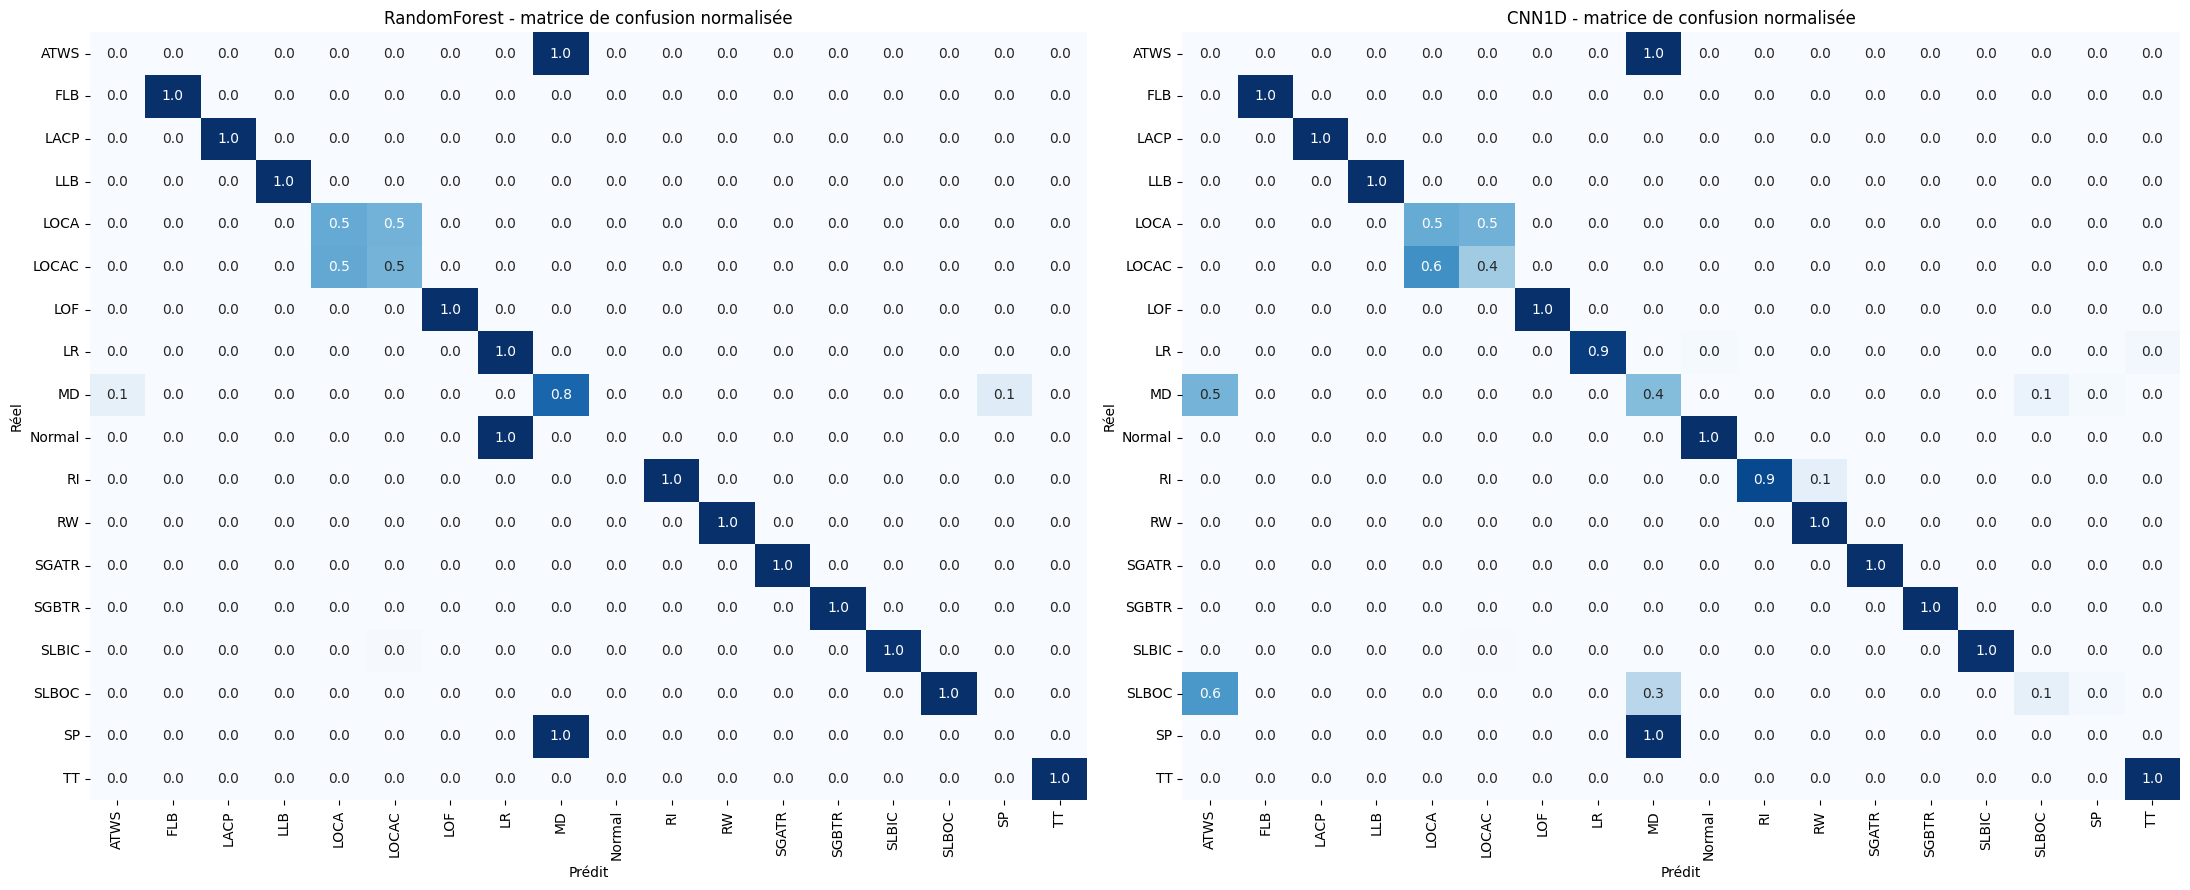

              precision    recall  f1-score   support

        ATWS       0.00      0.00      0.00         6
         FLB       1.00      1.00      1.00       114
        LACP       1.00      1.00      1.00         5
         LLB       1.00      1.00      1.00       318
        LOCA       0.41      0.51      0.45       213
       LOCAC       0.47      0.37      0.41       250
         LOF       1.00      1.00      1.00         5
          LR       1.00      0.95      0.97       318
          MD       0.62      0.44      0.52       342
      Normal       0.29      1.00      0.44         2
          RI       1.00      0.91      0.95       100
          RW       0.91      1.00      0.95        92
       SGATR       1.00      1.00      1.00       263
       SGBTR       1.00      1.00      1.00       256
       SLBIC       1.00      1.00      1.00       240
       SLBOC       0.50      0.09      0.15       271
          SP       0.00      0.00      0.00         5
          TT       0.44    

In [6]:
from sklearn.metrics import classification_report

best_name = max(models, key=lambda k: results[k]["f1"])
best = models[best_name]
preds = {"RandomForest": rf.predict(feats(Xte)), best_name: predict(best, Xte)}

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, (n, p) in zip(axes, preds.items()):
    cm = confusion_matrix(yte, p, labels=range(C), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".1f", xticklabels=classes, yticklabels=classes,
                cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{n} - matrice de confusion normalisée")
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=150); plt.show()

print(classification_report(yte, preds[best_name], labels=range(C),
                            target_names=classes, zero_division=0))

In [7]:
mask = np.isin(yte, [i for i in range(C) if (yte == i).sum() >= 50])
labs = np.unique(yte[mask])
allpreds = {"RandomForest": rf.predict(feats(Xte)), **{k: predict(m, Xte) for k, m in models.items()}}
res2 = pd.Series({k: f1_score(yte[mask], p[mask], average="macro", labels=labs) for k, p in allpreds.items()}).round(4)
print(f"Classes évaluées ({len(labs)}):", [classes[i] for i in labs])
res2.to_csv("results/f1_classes_robustes.csv"); res2

Classes évaluées (12): ['FLB', 'LLB', 'LOCA', 'LOCAC', 'LR', 'MD', 'RI', 'RW', 'SGATR', 'SGBTR', 'SLBIC', 'SLBOC']


,0
RandomForest,0.9050
CNN1D,0.7850
LSTM,0.7865
CNN_LSTM,0.8107


model,CNN1D,CNN_LSTM,LSTM,RandomForest
scenario,,,,
Aucune,0.693,0.692,0.677,0.765
Bruit 0.1,0.695,0.693,0.677,0.343
Bruit 0.3,0.694,0.675,0.672,0.279
Bruit 0.5,0.702,0.679,0.661,0.272
Capteurs HS 10%,0.598,0.654,0.616,0.751
Capteurs HS 30%,0.459,0.522,0.496,0.598


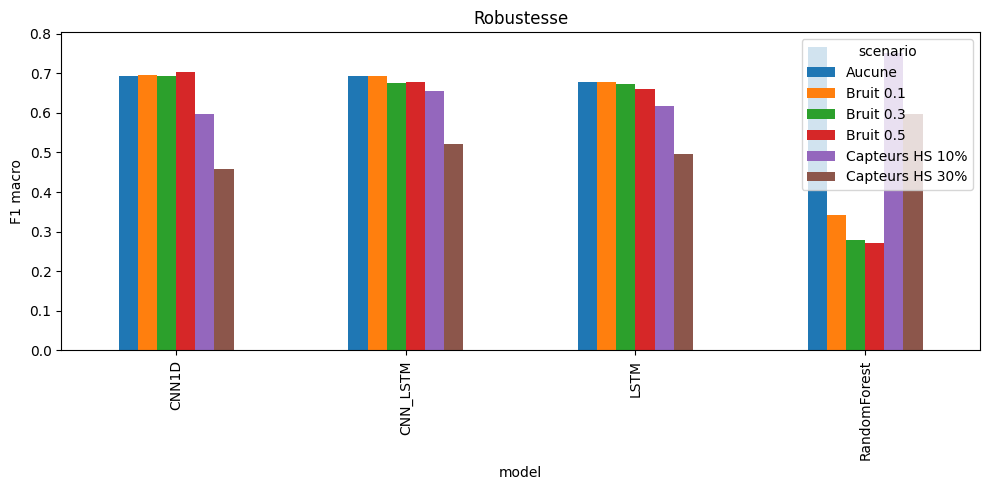

In [8]:
rng = np.random.default_rng(SEED)
def perturb(X, noise=0.0, drop=0.0):
    Xp = X + rng.normal(0, noise, X.shape).astype(np.float32) if noise > 0 else X.copy()
    if drop > 0:
        mask = rng.random((len(X), 1, X.shape[2])) < drop
        Xp = np.where(mask, 0.0, Xp).astype(np.float32)   # 0 = moyenne après normalisation
    return Xp

pred_fns = {"RandomForest": lambda X: rf.predict(feats(X)),
            **{k: (lambda X, m=m: predict(m, X)) for k, m in models.items()}}
rows = []
for scen, kw in [("Aucune", {}), ("Bruit 0.1", dict(noise=0.1)), ("Bruit 0.3", dict(noise=0.3)),
                 ("Bruit 0.5", dict(noise=0.5)), ("Capteurs HS 10%", dict(drop=0.1)),
                 ("Capteurs HS 30%", dict(drop=0.3))]:
    Xp = perturb(Xte, **kw)
    for name, fn in pred_fns.items():
        rows.append(dict(scenario=scen, model=name, f1=f1_score(yte, fn(Xp), average="macro")))
rob = pd.DataFrame(rows).pivot(index="scenario", columns="model", values="f1").round(3)
rob.to_csv("results/robustness.csv"); display(rob)
rob.T.plot(kind="bar", figsize=(10, 5), ylabel="F1 macro", title="Robustesse")
plt.tight_layout(); plt.savefig("results/robustness.png", dpi=150); plt.show()

In [9]:
def detection_delay(model):
    delays = []
    for gid in np.unique(g_te[g_te >= 0]):
        m = g_te == gid
        order = np.argsort(t_te[m]); yt = yte[m][order]
        if "normal" in classes[yt[0]].lower(): continue
        ok = predict(model, Xte[m][order]) == yt
        wrong = np.where(~ok)[0]
        k = 0 if len(wrong) == 0 else wrong[-1] + 1
        delays.append(t_te[m][order][k] + W if k < len(ok) else np.nan)
    d = np.array(delays, dtype=float)
    return np.nanmean(d), np.isnan(d).mean()

for name, m in models.items():
    mean_d, never = detection_delay(m)
    print(f"{name}: délai moyen = {mean_d:.1f} pas de temps | jamais stable = {never:.0%}")

CNN1D: délai moyen = 84.9 pas de temps | jamais stable = 19%
LSTM: délai moyen = 88.2 pas de temps | jamais stable = 21%
CNN_LSTM: délai moyen = 71.3 pas de temps | jamais stable = 21%


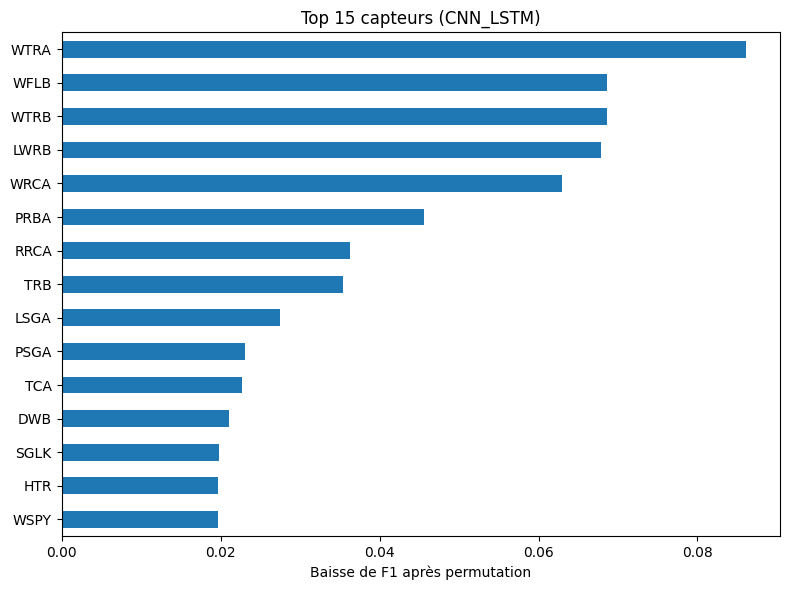

,0
WTRA,0.086076
WFLB,0.068644
WTRB,0.068571
LWRB,0.067837
WRCA,0.062939
PRBA,0.045623
RRCA,0.036223
TRB,0.035441
LSGA,0.027465
PSGA,0.023085


In [10]:
best_name = "CNN_LSTM"; best = models[best_name]
base = f1_score(yte, predict(best, Xte), average="macro")
imp = []
for j in range(F):
    Xp = Xte.copy()
    Xp[:, :, j] = Xp[np.random.permutation(len(Xp))][:, :, j]
    imp.append(base - f1_score(yte, predict(best, Xp), average="macro"))
top = pd.Series(imp, index=features).sort_values(ascending=False).head(15)
top.iloc[::-1].plot(kind="barh", figsize=(8, 6), title=f"Top 15 capteurs ({best_name})")
plt.xlabel("Baisse de F1 après permutation"); plt.tight_layout()
plt.savefig("results/sensor_importance.png", dpi=150); plt.show()
top.to_csv("results/sensor_importance.csv"); top

In [15]:
!rm -f results.zip
!zip -qr results.zip results
from google.colab import files; files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
used = {(c, n) for _, c, n, _ in runs}
for c in ["LOCA", "SGATR", "SLBOC", "LLB", "MD"]:
    nouveaux = [f for f in sorted((root / c).glob("*.csv")) if (c, f.name) not in used]
    if not nouveaux:
        print(c, ": pas de nouvelle simulation"); continue
    df = pd.read_csv(nouveaux[0])
    X = df[features].apply(pd.to_numeric, errors="coerce").ffill().fillna(0).values.astype(np.float32)
    X = norm(X)
    fen = np.stack([X[i:i+W] for i in range(len(X)-W+1)])
    pred = predict(models["CNN_LSTM"], fen)
    vote = np.bincount(pred, minlength=C).argmax()
    ok = (pred == classes.index(c)).mean()
    print(f"Accident réel : {c:6} | Diagnostic du modèle : {classes[vote]:6} | Bonnes réponses : {ok:.0%}")

Accident réel : LOCA   | Diagnostic du modèle : LOCAC  | Bonnes réponses : 17%
Accident réel : SGATR  | Diagnostic du modèle : MD     | Bonnes réponses : 0%
Accident réel : SLBOC  | Diagnostic du modèle : MD     | Bonnes réponses : 40%
Accident réel : LLB    | Diagnostic du modèle : MD     | Bonnes réponses : 0%
Accident réel : MD     | Diagnostic du modèle : MD     | Bonnes réponses : 67%


In [13]:
used = {(c, n) for _, c, n, _ in runs}
rows = []
for c in ["LOCA", "SGATR", "SLBOC", "LLB", "MD"]:
    nouveaux = [f for f in sorted((root / c).glob("*.csv")) if (c, f.name) not in used]
    pas = max(1, len(nouveaux) // 8)
    for f in nouveaux[::pas][:8]:
        df = pd.read_csv(f)
        X = norm(df[features].apply(pd.to_numeric, errors="coerce").ffill().fillna(0).values.astype(np.float32))
        fen = np.stack([X[i:i+W] for i in range(len(X) - W + 1)])
        ci = classes.index(c)
        for m in ["RandomForest", "CNN_LSTM"]:
            pred = rf.predict(feats(fen)) if m == "RandomForest" else predict(models[m], fen)
            rows.append(dict(accident=c, severite=f.stem, modele=m, bonnes_reponses=(pred == ci).mean()))
r = pd.DataFrame(rows)
r.to_csv("results/essai_simulations_inedites.csv", index=False)
display(r.pivot_table(index="accident", columns="modele", values="bonnes_reponses").round(2))
display(r.pivot_table(index=["accident", "severite"], columns="modele", values="bonnes_reponses").round(2))

modele,CNN_LSTM,RandomForest
accident,,
LLB,0.88,1.00
LOCA,0.46,0.39
MD,0.64,0.79
SGATR,0.83,1.00
SLBOC,0.41,0.93


modele             CNN_LSTM  RandomForest
accident severite                        
LLB      1             0.00          1.00
         18            1.00          1.00
         28            1.00          1.00
         40            1.00          1.00
         52            1.00          1.00
         59            1.00          1.00
         66            1.00          1.00
         75            1.00          1.00
LOCA     1             0.17          0.08
         2             0.08          0.31
         28            0.87          0.04
         38            1.00          0.94
         48            1.00          0.94
         6             0.02          0.08
         69            0.50          0.64
         8             0.00          0.07
MD       10            0.67          0.81
         21            0.67          0.81
         29            0.66          0.80
         41            0.67          0.81
         51            0.61          0.78
         60            0.62          0.78
         73            0.61          0.78
         84            0.61          0.78
SGATR    1             0.00          1.00
         18            1.00          1.00
         26            1.00          1.00
         35            1.00          1.00
         5             0.65          1.00
         59            1.00          1.00
         68            1.00          1.00
         77            1.00          1.00
SLBOC    1             0.40          0.45
         19            0.41          1.00
         28            0.43          1.00
         4             0.39          0.98
         51            0.48          1.00
         60            0.36          1.00
         7             0.39          1.00
         8             0.39          1.00

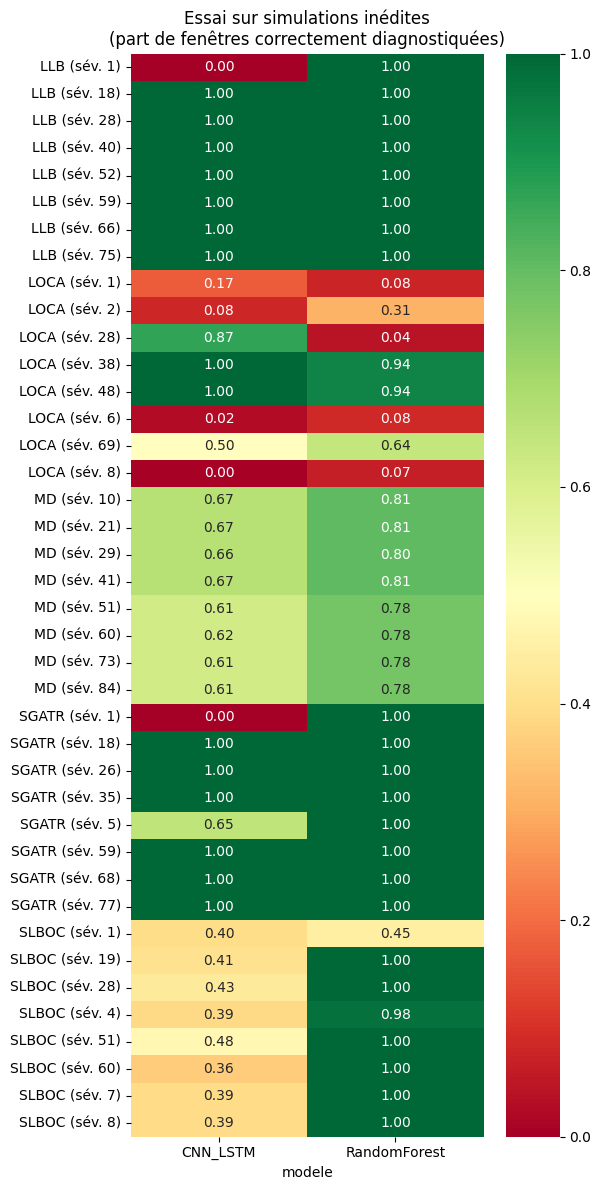

In [14]:
piv = r.pivot_table(index=["accident", "severite"], columns="modele", values="bonnes_reponses")
piv.index = [f"{a} (sév. {s})" for a, s in piv.index]
plt.figure(figsize=(6, 12)); sns.heatmap(piv, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Essai sur simulations inédites\n(part de fenêtres correctement diagnostiquées)")
plt.tight_layout(); plt.savefig("results/essai_heatmap.png", dpi=150); plt.show()